# 03 · Modelo final y entrega de scores

Este notebook consume la decisión interior auditada en el notebook 02, reajusta
**todos los candidatos** con sus parámetros seleccionados y puntúa las 113.923 filas
de producción en su orden original.

En el régimen `normales` se utilizan todas las filas `Class=0`; en `todos` y
`supervisado`, toda construcción. El AE utiliza su validación interna para fijar épocas
y luego reajusta con todas las filas recibidas.

La entrega contiene una sola columna `score`: **mayor score, mayor sospecha**.
No contiene decisiones binarias, probabilidades de fraude garantizadas ni métricas
de producción. Las etiquetas de producción no están disponibles.

In [1]:
from pathlib import Path
import hashlib
import inspect
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Code, Markdown, display

RAIZ = Path.cwd().resolve()
assert (RAIZ / "credit_card_construction.csv.zip").is_file(), "Ejecutar desde la raíz del taller."
assert Path(sys.prefix).resolve() == (RAIZ / ".venv").resolve(), "Seleccionar el kernel de .venv."
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from estudio_datos.comparativa_full import experimento, modelos
SALIDA = experimento.SALIDA
MODULOS = RAIZ / "estudio_datos" / "comparativa_full"

def leer_json(ruta):
    return json.loads(Path(ruta).read_text(encoding="utf-8"))

def sha256(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", None)
print("Python:", sys.executable)
print("Resultados:", SALIDA)

Python: /Users/jchulvi/projects/Taller_Deteccion_Anomalias/.venv/bin/python
Resultados: /Users/jchulvi/projects/Taller_Deteccion_Anomalias/estudio_datos/comparativa_full/resultados


## Comprobar la procedencia de la decisión

La familia, el régimen y los hiperparámetros provienen de la selección interior
sobre construcción completa (`outer=-1`). Se mantienen las huellas de fuentes y
decisiones. Producción solo se utiliza después para inferencia.

In [2]:
from estudio_datos.comparativa_full import finalizar

seleccion_previa = leer_json(SALIDA / "seleccion_final.json")
assert seleccion_previa["metricas_exteriores_usadas_para_elegir"] is False
assert seleccion_previa["familia"] != "ecod_cohorte"
for nombre in ("protocolo.json", "integridad_datos.json", "tabla_candidatos_interiores.csv"):
    assert sha256(SALIDA / nombre) == seleccion_previa["fuentes"][nombre]
assert sha256(MODULOS / "analizar.py") == seleccion_previa["fuentes"]["analizar.py"]
display(pd.Series({k: seleccion_previa[k] for k in [
    "familia", "regimen", "config", "parametros", "origen_seleccion",
    "filas_refit_esperadas", "filas_produccion_esperadas", "protocolo"
]}).to_frame("decisión"))
display(Code(inspect.getsource(finalizar.ajustar_final), language="python"))
display(Code(inspect.getsource(finalizar.finalizar_todos), language="python"))
display(Code(inspect.getsource(finalizar.entregar), language="python"))

,decisión
familia,lightgbm
regimen,supervisado
config,3
parametros,"{'n_estimators': 500, 'learning_rate': 0.05, 'num_leaves': 15, 'min_child_samples': 50, 'reg_lambda': 1.0,..."
origen_seleccion,outer=-1; tres folds interiores sobre construcción completa
filas_refit_esperadas,170884
filas_produccion_esperadas,113923
protocolo,638141edb70c6551f61114f7f3526db2f8d67d838f706ae3216808a220628201


def ajustar_final(familia, regimen, hilos=2):
    X, y, grupos, particiones, protocolo = cargar()
    particiones.close()
    assert versiones() == protocolo["versiones"] and platform.python_version() == protocolo["python"]
    seleccion = json.loads((SALIDA / "seleccion_final.json").read_text())
    assert seleccion["protocolo"] == protocolo["id"]
    ruta_decision = SALIDA / "decisiones" / f"{familia}__{regimen}.json"
    assert digest_bytes(ruta_decision.read_bytes()) == seleccion["fuentes"]["decisiones"][ruta_decision.name]
    decisiones = json.loads(ruta_decision.read_text())
    decision = next(d for d in decisiones if d["outer"] == -1)
    assert decision["protocolo"] == protocolo["id"]
    config = decision["ganador"]["config"]
    params = CONFIGURACIONES[familia][config]
    fit_idx = np.flatnonzero(y == 0) if regimen == "normales" else np.arange(len(y))
    Xp = np.load(SALIDA / "X_produccion.npy", mmap_mode="r")
    ruta = SALIDA / "finales" / f"{familia}__{regimen}"
    ruta.parent.mkdir(exist_ok=True)
    ident = {"protocolo": protocolo["id"], "datos": protocolo["integridad_preparados"],
             "familia": familia, "regimen": regimen, "config": config, "parametros": params,
             "semilla": SEMILLA + 99999, "hilos": hilos, "codigo": codigo_modelo(familia),
             "codigo_finalizacion": digest_bytes(Path(__file__).read_bytes()),
             "decision": digest_json(decision)}
    if ruta.with_suffix(".json").exists():
        previo = json.loads(ruta.with_suffix(".json").read_text())
        if previo["identidad"] == ident:
            for ext, key in [(".csv", "scores_sha256"), (".joblib", "modelo_sha256")]:
                if digest_bytes(ruta.with_suffix(ext).read_bytes()) != previo[key]:
                    raise RuntimeError(f"Artefacto final alterado: {ruta}{ext}")
            return previo
    inicio = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        modelo = Modelo(familia, params, ident["semilla"], hilos).fit(X[fit_idx], y[fit_idx])
        ajustado = time.perf_counter()
        scores = modelo.score_samples(Xp)
        puntuado = time.perf_counter()
    assert scores.shape == (113923,) and np.isfinite(scores).all()
    # Verificación con filas reales: el resultado debe sobrevivir serialización.
    # kNN: la distancia euclídea por productos escalares puede perder precisión
    # cerca de cero. Se verificaron vecinos idénticos y ranking sin cambios en
    # la muestra; la resta directa confirmó un error absoluto menor de 1e-7.
    tolerancia = {"rtol": 1e-6, "atol": 1e-7 if familia == "knn" else 1e-8}
    delta_orden = None
    joblib.dump(modelo, ruta.with_suffix(".joblib"), compress=3)
    recargado = joblib.load(ruta.with_suffix(".joblib"))
    if familia == "ecod_cohorte":
        # La misma cohorte completa es parte explícita del contrato del original.
        muestra_scores = recargado.score_samples(Xp)
        delta_serial = float(np.max(np.abs(muestra_scores - scores)))
        np.testing.assert_allclose(muestra_scores, scores, **tolerancia)
        invariant = None
    else:
        indices = np.arange(0, len(Xp), max(1, len(Xp) // 257))
        muestra_scores = recargado.score_samples(Xp[indices])
        delta_serial = float(np.max(np.abs(muestra_scores - scores[indices])))
        np.testing.assert_allclose(muestra_scores, scores[indices], **tolerancia)
        invertidos = recargado.score_samples(Xp[indices[::-1]])[::-1]
        delta_orden = float(np.max(np.abs(invertidos - muestra_scores)))
        np.testing.assert_allclose(invertidos, muestra_scores, **tolerancia)
        invariant = True
    pd.DataFrame({"score": scores}).to_csv(ruta.with_suffix(".csv"), index=False)
    meta = {"identidad": ident, "filas_fit": len(fit_idx), "filas_produccion": len(scores),
            "tiempos": {"fit_s": ajustado-inicio, "score_s": puntuado-ajustado},
            "entrenamiento": modelo.training_info_, "avis

def finalizar_todos(hilos=2, trabajos=4):
    """Reajusta combinaciones independientes y conserva su orden canónico."""
    seleccion = json.loads((SALIDA / "seleccion_final.json").read_text())
    pares = [(f, r) for f in CONFIGURACIONES for r in regimenes(f)]
    if trabajos == 1:
        modelos = [ajustar_final(f, r, hilos) for f, r in pares]
    else:
        with ProcessPoolExecutor(
            max_workers=trabajos, mp_context=multiprocessing.get_context("spawn")
        ) as ejecutor:
            futuros = [ejecutor.submit(ajustar_final, f, r, hilos) for f, r in pares]
            modelos = [futuro.result() for futuro in futuros]
    escribir_json(SALIDA / "resumen_refits.json", modelos)
    return seleccion, modelos

def entregar(seleccion=None):
    """Acredita la decisión, los 24 reajustes y la correspondencia de la entrega."""
    if seleccion is None:
        seleccion = json.loads((SALIDA / "seleccion_final.json").read_text())
    _, y, _, particiones, protocolo = cargar()
    particiones.close()
    auditoria_cv = json.loads((SALIDA / "auditoria_completitud.json").read_text())
    assert auditoria_cv["estado"] == "completo" and auditoria_cv["protocolo"] == protocolo["id"]
    assert auditoria_cv["familias_regimenes"] == 24
    assert auditoria_cv["ajustes_verificados"] == 1542
    assert auditoria_cv["evaluaciones_exteriores"] == 120
    familia, regimen = seleccion["familia"], seleccion["regimen"]
    assert familia != "ecod_cohorte", "La cohorte no participa en la selección principal."
    assert seleccion["protocolo"] == protocolo["id"]
    assert seleccion["parametros"] == CONFIGURACIONES[familia][seleccion["config"]]
    verificados = []
    for f in CONFIGURACIONES:
        for r in regimenes(f):
            base = SALIDA / "finales" / f"{f}__{r}"
            meta = json.loads(base.with_suffix(".json").read_text())
            ruta_decision = SALIDA / "decisiones" / f"{f}__{r}.json"
            assert digest_bytes(ruta_decision.read_bytes()) == seleccion["fuentes"]["decisiones"][ruta_decision.name]
            decision = next(d for d in json.loads(ruta_decision.read_text()) if d["outer"] == -1)
            assert meta["identidad"]["protocolo"] == protocolo["id"]
            assert meta["identidad"]["decision"] == digest_json(decision)
            assert meta["identidad"]["familia"] == f and meta["identidad"]["regimen"] == r
            assert meta["identidad"]["config"] == decision["ganador"]["config"]
            assert meta["identidad"]["parametros"] == CONFIGURACIONES[f][decision["ganador"]["config"]]
            assert meta["identidad"]["codigo"] == codigo_modelo(f)
            assert meta["identidad"]["codigo_finalizacion"] == digest_bytes(Path(__file__).read_bytes())
            assert meta["identidad"]["datos"] == protocolo["integridad_preparados"]
            assert meta["filas_fit"] == (int((y == 0).sum()) if r == "normales" else len(y))
            assert meta["filas_produccion"] == 113923
            assert digest_bytes(base.with_suffix(".csv").read_bytes()) == meta["scores_sha256"]
            assert digest_bytes(base.with_suffix(".joblib").read_bytes()) == meta["modelo_sha256"]
            df = pd.read_csv(base.with_suffix(".csv"))
            assert df.shape == (113923, 1) and list(df.columns) == ["score"]
            assert np.isfinite(df.score.to_numpy()).all()
            if f != "ecod_cohorte":
                assert meta["invariante_lote"] is True
            verificados.append({"familia": f, "regimen": r, "filas_fit": meta["filas_fit"],
                                "scores_sha256": meta["scores_sha256"]})
    fuente = SALIDA / "finales" / f"{familia}__{regimen}.csv"
    entrega = RAIZ / "entrega_scores.csv"
    entrega.write_bytes(fuente.read_bytes())
    assert digest_bytes(entrega.read_bytes()) == digest_bytes(fuente.read_bytes())
    resultado = {
        "estado": "completo", "familia": familia, "regimen": regimen,
        "parametros": seleccion["parametros"], "filas": 113923, "columnas": ["score"],
        "mayor_score": "mayor sospecha de fraude; no probabilidad necesariamente calibrada",
        "ruta_entrega": str(entrega.relative_to(RAIZ)),
        "modelo": str((SALIDA / "finales" / f"{familia}__{regimen}.joblib").relative_to(RAIZ)),
        "orden": "Mismo orden de X_produccion.npy, verificado frente al ZIP de producción.",
        "scores_sha256": digest_bytes(entrega.read_bytes()),
        "seleccion_sha256": digest_bytes((SALIDA / "seleccion_final.json").read_bytes()),
        "auditoria_cv_sha256": digest_bytes((SALIDA / "auditoria_completitud.json").read_bytes()),
        "protocolo": protocolo["id"], "refits_verificados": verificados,
        "refit_final_verificado": True, "produccion_v

In [3]:
# Conclusión calculada a partir de las tablas auditadas; no se anticipan resultados.
resumen_comparativa = pd.read_csv(SALIDA / "tabla_resumen_familia_regimen.csv")
procedimiento_anidado = pd.read_csv(SALIDA / "tabla_procedimiento_anidado.csv")
mascara_elegido = (
    resumen_comparativa["familia"].eq(seleccion_previa["familia"])
    & resumen_comparativa["regimen"].eq(seleccion_previa["regimen"])
)
assert int(mascara_elegido.sum()) == 1
elegido_exterior = resumen_comparativa.loc[mascara_elegido].iloc[0]
assert int(elegido_exterior["folds"]) == 5
assert len(procedimiento_anidado) == 5
ap_procedimiento = procedimiento_anidado["ap"].mean()
sd_procedimiento = procedimiento_anidado["ap"].std(ddof=1)
delta_procedimiento = procedimiento_anidado["delta_ap_gmm"].mean()
ap_interior = seleccion_previa["criterios_interiores"]["ap_media"]
parametros_texto = json.dumps(seleccion_previa["parametros"], ensure_ascii=False, sort_keys=True)

display(Markdown(
    "### Resultado de la selección\n\n"
    f"Se elige **{seleccion_previa['familia']} / {seleccion_previa['regimen']}**, "
    f"con parámetros `{parametros_texto}`. Su AP interior media sobre construcción completa "
    f"es **{ap_interior:.4f}**. La regla fijada es: {seleccion_previa['regla']}\n\n"
    f"La familia y el régimen elegidos obtienen una AP exterior de "
    f"**{elegido_exterior['ap_media']:.4f} ± {elegido_exterior['ap_sd']:.4f}** "
    "(media y desviación entre cinco folds, con parámetros elegidos dentro de cada fold). "
    f"La diferencia media pareada frente al GMM fijo es "
    f"**{elegido_exterior['delta_ap_gmm_media']:+.4f} AP**. "
    "Esta es una descripción retrospectiva de esa familia, no una medición del reajuste final.\n\n"
    f"Por separado, el **procedimiento anidado de selección entre familias** obtiene "
    f"**{ap_procedimiento:.4f} ± {sd_procedimiento:.4f} AP**, "
    f"con diferencia pareada media de **{delta_procedimiento:+.4f} AP** frente al GMM fijo. "
    "En cada evaluación exterior, la elección se tomó usando solo sus folds interiores.\n\n"
    "**Límite:** la desviación es descriptiva, no un intervalo de confianza. "
    + seleccion_previa["limites"]
    + " No hay etiquetas para medir el rendimiento en producción."
))
display(Markdown(
    "**Cinco candidatos con mayor AP exterior media, como comparación descriptiva.** "
    "Este ranking no sustituye la decisión interior y puede incluir ECOD por cohorte, "
    "que no es elegible para la entrega."
))
display(resumen_comparativa.sort_values(
    ["ap_media", "familia", "regimen"], ascending=[False, True, True], kind="stable"
).head(5)[[
    "familia", "regimen", "elegible", "ap_media", "ap_sd", "delta_ap_gmm_media"
]])

### Resultado de la selección

Se elige **lightgbm / supervisado**, con parámetros `{"class_weight": "balanced", "learning_rate": 0.05, "min_child_samples": 50, "n_estimators": 500, "num_leaves": 15, "reg_lambda": 1.0}`. Su AP interior media sobre construcción completa es **0.8472**. La regla fijada es: AP media interior máxima; únicamente ante igualdad exacta: mayor recall@1%, menor tiempo medio de ajuste, nombre de familia, régimen e índice de configuración. ECOD por cohorte no es elegible.

La familia y el régimen elegidos obtienen una AP exterior de **0.8414 ± 0.0448** (media y desviación entre cinco folds, con parámetros elegidos dentro de cada fold). La diferencia media pareada frente al GMM fijo es **+0.1933 AP**. Esta es una descripción retrospectiva de esa familia, no una medición del reajuste final.

Por separado, el **procedimiento anidado de selección entre familias** obtiene **0.8414 ± 0.0448 AP**, con diferencia pareada media de **+0.1933 AP** frente al GMM fijo. En cada evaluación exterior, la elección se tomó usando solo sus folds interiores.

**Límite:** la desviación es descriptiva, no un intervalo de confianza. Validación interna exploratoria de datos previamente examinados; no es un test independiente. AP resumida por fold, sin concatenar scores crudos. La evaluación del procedimiento selecciona familia y configuración solo con los folds interiores de cada entrenamiento exterior. No hay etiquetas para medir el rendimiento en producción.

**Cinco candidatos con mayor AP exterior media, como comparación descriptiva.** Este ranking no sustituye la decisión interior y puede incluir ECOD por cohorte, que no es elegible para la entrega.

,familia,regimen,elegible,ap_media,ap_sd,delta_ap_gmm_media
0,lightgbm,supervisado,True,0.841364,0.044755,0.193329
1,random_forest,supervisado,True,0.834397,0.029824,0.186361
2,logistica,supervisado,True,0.760769,0.048248,0.112734
3,autoencoder,normales,True,0.657655,0.131401,0.009619
4,gmm_fijo,normales,True,0.648035,0.085213,0.000000


## Reajustar todos los modelos y puntuar producción

Cada pareja familia/régimen se reajusta sobre la totalidad de sus filas permitidas.
Se ejecutan hasta cuatro reajustes independientes en procesos separados, con dos
hilos por modelo; se espera a todos antes de medir las cinco inferencias del elegido.
Se conserva el estimador serializado, el CSV de scores y los metadatos con tamaños,
parámetros y tiempos. Los artefactos existentes solo se reutilizan si sus identidades
y hashes coinciden.

ECOD por cohorte también se conserva como comparación separada, consultando producción
completa; sigue excluido de la selección principal. Esta celda puede tardar en un
primer recorrido y es reanudable.

In [4]:
seleccion_final, refits = finalizar.finalizar_todos(hilos=2)
assert seleccion_final == seleccion_previa
esperados = sum(len(modelos.regimenes(f)) for f in modelos.CONFIGURACIONES)
assert len(refits) == esperados
tabla_refits = pd.DataFrame([
    {"familia": r["identidad"]["familia"], "regimen": r["identidad"]["regimen"],
     "config": r["identidad"]["config"], "filas_fit": r["filas_fit"],
     "filas_produccion": r["filas_produccion"], **r["tiempos"],
     "invariante_lote": r["invariante_lote"],
     "delta_serializacion": r["delta_serializacion"],
     "delta_orden_lote": r["delta_orden_lote"],
     "atol": r["tolerancia_verificacion"]["atol"]}
    for r in refits
])
assert tabla_refits["filas_produccion"].eq(113923).all()
display(tabla_refits)

REFIT COMPLETO constante/referencia: 170884 filas, 113923 scores; fit=0.02s


REFIT COMPLETO univariante/supervisado: 170884 filas, 113923 scores; fit=0.65s


REFIT COMPLETO gmm/normales: 170589 filas, 113923 scores; fit=2.76s


REFIT COMPLETO gmm/todos: 170884 filas, 113923 scores; fit=2.95s


REFIT COMPLETO gmm_fijo/normales: 170589 filas, 113923 scores; fit=3.37s
REFIT COMPLETO pca/normales: 170589 filas, 113923 scores; fit=0.14s


...

REFIT COMPLETO ecod_cohorte/todos: 170884 filas, 113923 scores; fit=0.93s


REFIT COMPLETO autoencoder/normales: 170589 filas, 113923 scores; fit=31.29s
REFIT COMPLETO autoencoder/todos: 170884 filas, 113923 scores; fit=31.11s


REFIT COMPLETO lightgbm/supervisado: 170884 filas, 113923 scores; fit=3.55s


REFIT COMPLETO random_forest/supervisado: 170884 filas, 113923 scores; fit=56.65s


,familia,regimen,config,filas_fit,filas_produccion,fit_s,score_s,invariante_lote,delta_serializacion,delta_orden_lote,atol
0,constante,referencia,0,170884,113923,0.023143,0.001236,True,0.000000e+00,0.000000e+00,1.000000e-08
1,univariante,supervisado,0,170884,113923,0.645113,0.001587,True,0.000000e+00,0.000000e+00,1.000000e-08
2,gmm_fijo,normales,0,170589,113923,3.369860,0.048487,True,0.000000e+00,0.000000e+00,1.000000e-08
3,gmm,normales,3,170589,113923,2.763772,0.056093,True,0.000000e+00,0.000000e+00,1.000000e-08
4,gmm,todos,4,170884,113923,2.953698,0.041096,True,0.000000e+00,0.000000e+00,1.000000e-08
5,isolation_forest,normales,2,170589,113923,6.393164,2.377635,True,0.000000e+00,0.000000e+00,1.000000e-08
6,isolation_forest,todos,1,170884,113923,1.409861,1.688209,True,0.000000e+00,0.000000e+00,1.000000e-08
7,pca,normales,3,170589,113923,0.141713,0.019290,True,0.000000e+00,0.000000e+00,1.000000e-08
8,pca,todos,0,170884,113923,0.103057,0.017647,True,0.000000e+00,0.000000e+00,1.000000e-08
9,lof,normales,2,170589,113923,36.322283,24.855713,True,0.000000e+00,3.552714e-15,1.000000e-08


In [5]:
# La decisión identifica exactamente el modelo y su fichero de scores.
clave = f"{seleccion_final['familia']}__{seleccion_final['regimen']}"
base_final = SALIDA / "finales" / clave
origen_csv = base_final.with_suffix(".csv")
origen_modelo = base_final.with_suffix(".joblib")
meta_modelo = leer_json(base_final.with_suffix(".json"))
assert meta_modelo["identidad"]["familia"] == seleccion_final["familia"]
assert meta_modelo["identidad"]["regimen"] == seleccion_final["regimen"]
assert meta_modelo["identidad"]["config"] == seleccion_final["config"]
assert meta_modelo["identidad"]["parametros"] == seleccion_final["parametros"]
assert meta_modelo["identidad"]["protocolo"] == seleccion_final["protocolo"]
assert meta_modelo["filas_fit"] == seleccion_final["filas_refit_esperadas"]
assert sha256(origen_csv) == meta_modelo["scores_sha256"]
assert sha256(origen_modelo) == meta_modelo["modelo_sha256"]
display(pd.DataFrame([
    {"artefacto": "decisión", "ruta": str((SALIDA / "seleccion_final.json").relative_to(RAIZ))},
    {"artefacto": "modelo", "ruta": str(origen_modelo.relative_to(RAIZ))},
    {"artefacto": "scores originales", "ruta": str(origen_csv.relative_to(RAIZ))},
    {"artefacto": "metadatos del ajuste", "ruta": str(base_final.with_suffix(".json").relative_to(RAIZ))}
]))
print(json.dumps(meta_modelo, indent=2, ensure_ascii=False))

,artefacto,ruta
0,decisión,estudio_datos/comparativa_full/resultados/seleccion_final.json
1,modelo,estudio_datos/comparativa_full/resultados/finales/lightgbm__supervisado.joblib
2,scores originales,estudio_datos/comparativa_full/resultados/finales/lightgbm__supervisado.csv
3,metadatos del ajuste,estudio_datos/comparativa_full/resultados/finales/lightgbm__supervisado.json


{
  "identidad": {
    "protocolo": "638141edb70c6551f61114f7f3526db2f8d67d838f706ae3216808a220628201",
    "datos": {
      "X.npy": "797d4be9c7598ba85b766a7871e87e9ed0eab97715af09ec65c88ee028e28df3",
      "y.npy": "7c793d6c0d9c8a583a4ed44af8c0cb6edf6c325b7f74f0cf2627a9eb64410197",
      "grupos.npy": "300c85e51790caebd642c08c9dcfd6186c64ac7ba506397d3952773dab9f031c",
      "X_produccion.npy": "6259fbef314607e7e0e97efc8cd84de186f79c7dea142eabb4fe6cddf9f2294f",
      "particiones.npz": "bc7c03b2a02c299f6d4ec38a68d5e84213a898fafcef664107326a97529c5456"
    },
    "familia": "lightgbm",
    "regimen": "supervisado",
    "config": 3,
    "parametros": {
      "n_estimators": 500,
      "learning_rate": 0.05,
      "num_leaves": 15,
      "min_child_samples": 50,
      "reg_lambda": 1.0,
      "class_weight": "balanced"
    },
    "semilla": 20361019,
    "hilos": 2,
    "codigo": {
      "modelos.py": "926a3eb0b0dcc3de4aa6b70f2f51a8cf5f413299155bc3c0c0c0ef028ac06951",
      "experimento.

## Verificar las 113.923 filas, el orden y la integridad

Se comprueba que los predictores preparados coinciden exactamente con el ZIP original
y que las etiquetas de producción siguen ausentes. La función de entrega verifica
todos los reajustes y conserva las identidades y hashes antes de copiar el CSV elegido.
La auditoría de validación y la decisión original permanecen intactas:
`auditoria_entrega.json` y `estado_entrega.json` acreditan esta fase posterior.

La igualdad entre lotes se comprueba con tolerancia numérica: `rtol=1e-6` y
`atol=1e-8`, salvo kNN (`atol=1e-7`). En una consulta de kNN la fórmula euclídea
por productos escalares presentó una diferencia de 3,82e-8 al invertir el lote.
El contraste por resta directa confirmó redondeo: mismos vecinos y mismo ranking
en las 258 consultas comprobadas. La diferencia y la tolerancia quedan registradas;
no se modificaron el algoritmo ni los scores de validación.
[Diagnóstico numérico](estudio_datos/comparativa_full/resultados/logs/diagnostico_precision_knn.json).

In [6]:
X, y, grupos, archivo_particiones, protocolo = experimento.cargar()
archivo_particiones.close()
X_produccion = np.load(SALIDA / "X_produccion.npy", mmap_mode="r")
original = pd.read_csv(RAIZ / "credit_card_production.csv.zip")
assert original.shape == (113923, 22)
assert original["Class"].isna().all()
assert sha256(RAIZ / "credit_card_production.csv.zip") == protocolo["datos_sha256"]["production"]
np.testing.assert_array_equal(
    original[protocolo["predictores"]].to_numpy(dtype=np.float64), X_produccion
)
scores_archivo = pd.read_csv(origen_csv, float_precision="round_trip")
assert scores_archivo.shape == (113923, 1)
assert list(scores_archivo.columns) == ["score"]
assert np.isfinite(scores_archivo["score"].to_numpy()).all()

print("Predictores de producción verificados frente al ZIP; CSV completo y finito.")

Predictores de producción verificados frente al ZIP; CSV completo y finito.


In [7]:
auditoria_entrega = finalizar.entregar(seleccion_final)
entrega = RAIZ / auditoria_entrega["ruta_entrega"]
assert auditoria_entrega["estado"] == "completo"
assert auditoria_entrega["refit_final_verificado"] is True
assert auditoria_entrega["produccion_verificada"] is True
assert auditoria_entrega["familia"] == seleccion_final["familia"]
assert auditoria_entrega["regimen"] == seleccion_final["regimen"]
assert sha256(entrega) == sha256(origen_csv) == meta_modelo["scores_sha256"]
assert sha256(entrega) == auditoria_entrega["scores_sha256"]
assert sha256(SALIDA / "seleccion_final.json") == auditoria_entrega["seleccion_sha256"]
assert sha256(SALIDA / "auditoria_completitud.json") == auditoria_entrega["auditoria_cv_sha256"]
tabla_entrega = pd.read_csv(entrega, float_precision="round_trip")
assert tabla_entrega.shape == (113923, 1)
assert list(tabla_entrega.columns) == ["score"]
assert np.isfinite(tabla_entrega["score"].to_numpy()).all()
np.testing.assert_array_equal(tabla_entrega["score"].to_numpy(),
                              scores_archivo["score"].to_numpy())

assert leer_json(SALIDA / "seleccion_final.json") == seleccion_previa
assert leer_json(SALIDA / "estado_entrega.json")["estado"] == "completo"
display(pd.Series({k: v for k, v in auditoria_entrega.items()
                   if k != "refits_verificados"}).to_frame("verificación"))
display(pd.DataFrame(auditoria_entrega["refits_verificados"]))

,verificación
estado,completo
familia,lightgbm
regimen,supervisado
parametros,"{'n_estimators': 500, 'learning_rate': 0.05, 'num_leaves': 15, 'min_child_samples': 50, 'reg_lambda': 1.0,..."
filas,113923
columnas,[score]
mayor_score,mayor sospecha de fraude; no probabilidad necesariamente calibrada
ruta_entrega,entrega_scores.csv
modelo,estudio_datos/comparativa_full/resultados/finales/lightgbm__supervisado.joblib
orden,"Mismo orden de X_produccion.npy, verificado frente al ZIP de producción."


,familia,regimen,filas_fit,scores_sha256
0,constante,referencia,170884,ff0495491e2da234f6bec5b2fd22b3e130cbb1009a3d5caad98a5a7c962a27f9
1,univariante,supervisado,170884,26f7dca585961e0ab629acae9793e2b35fd6edc1b97f8cb0fed0579dd531fa3d
2,gmm_fijo,normales,170589,7735680ff5e6cd784dd8b41371c99476c4f83a1482199aa1cf6915bc6d6e3dfd
3,gmm,normales,170589,090051935ab54b8448d3a22939e59846426ac4361ff5d424f89c23685f87de6e
4,gmm,todos,170884,f9dd4db3eb957311d24c5bb98e901e4a3f5eee74de338c97464f306faf4b017c
5,isolation_forest,normales,170589,f9d9bdc69719b87b6ff18c32bd7ffcde5f6b6d84e0dc32bc9284bce13802db7f
6,isolation_forest,todos,170884,4998b976d2c72d53db80b9478946a4d4082f90647b52b054ead6b329b1423026
7,pca,normales,170589,75db8637638d71d194a21d3f912e53ee77ce0db90f06d9c99e552014af5e0de0
8,pca,todos,170884,099e49e87244aeb4a22778171fe6300990022bfa316991e8b194b6404d9678dd
9,lof,normales,170589,0900d43000393dc37d89ad8272c72d5b57337c2650e8950a642659a299b597b8


## Serialización y cinco inferencias completas

Se recarga una vez el modelo guardado y se realizan **cinco inferencias consecutivas
sobre las 113.923 filas**, sin volver a ajustar ningún parámetro. Cada vector debe
coincidir con el CSV en el orden original, dentro de la tolerancia numérica indicada.

Se cronometra la puntuación completa; se excluyen la carga del modelo y las comprobaciones
posteriores. La mediana y el rango intercuartílico describen estas cinco mediciones locales.
Incluyen la primera llamada después de cargar el modelo y la carga real del Mac compartido;
no certifican la latencia ni el rendimiento de detección en producción.

In [8]:
import joblib
import time

modelo_recargado = joblib.load(origen_modelo)
referencia = tabla_entrega["score"].to_numpy()
repeticiones = []
for repeticion in range(1, 6):
    inicio = time.perf_counter()
    scores_en_orden_original = modelo_recargado.score_samples(X_produccion)
    segundos = time.perf_counter() - inicio
    assert scores_en_orden_original.shape == (113923,)
    assert np.isfinite(scores_en_orden_original).all()
    np.testing.assert_allclose(referencia, scores_en_orden_original, rtol=1e-6, atol=1e-8)
    repeticiones.append({
        "repeticion": repeticion, "filas": len(scores_en_orden_original),
        "segundos": segundos,
        "delta_maximo_vs_csv": float(np.max(np.abs(referencia - scores_en_orden_original))),
        "scores_coinciden": True
    })
tiempos = np.array([r["segundos"] for r in repeticiones])
q25, q75 = np.quantile(tiempos, [0.25, 0.75])
medicion = {
    "familia": seleccion_final["familia"], "regimen": seleccion_final["regimen"],
    "filas_por_inferencia": 113923, "repeticiones": repeticiones,
    "segundos_mediana": float(np.median(tiempos)),
    "segundos_q25": float(q25), "segundos_q75": float(q75),
    "segundos_iqr": float(q75 - q25),
    "modelo_sha256": sha256(origen_modelo), "scores_sha256": sha256(entrega),
    "auditoria_entrega_sha256": sha256(SALIDA / "auditoria_entrega.json"),
    "orden_verificado_en_todas_las_filas": True,
    "refits_adicionales": 0,
    "alcance": "Cinco inferencias locales completas; carga real del Mac; no latencia de producción certificada."
}
experimento.escribir_json(SALIDA / "tiempos_inferencia_entrega.json", medicion)
display(pd.DataFrame(repeticiones))
display(pd.Series({k: v for k, v in medicion.items()
                   if k != "repeticiones"}).to_frame("medición"))

,repeticion,filas,segundos,delta_maximo_vs_csv,scores_coinciden
0,1,113923,1.377993,0.0,True
1,2,113923,1.323633,0.0,True
2,3,113923,1.340283,0.0,True
3,4,113923,1.322284,0.0,True
4,5,113923,1.323368,0.0,True


,medición
familia,lightgbm
regimen,supervisado
filas_por_inferencia,113923
segundos_mediana,1.323633
segundos_q25,1.323368
segundos_q75,1.340283
segundos_iqr,0.016914
modelo_sha256,260ff22677971f9793ae2d631d14d64a3d1962ea40aea09885f58a1089b0178a
scores_sha256,5a093f11bf0ba42e4d1f1e2066223dc51aced23da77405b946b52526d1b85823
auditoria_entrega_sha256,99254beca7f976e796dab59cb4bb2b2a2103191a2450861a3e46e820998805df


## Distribución descriptiva de los scores de entrega

Estos resúmenes describen los valores producidos por el modelo. **No miden detección
de fraude en producción**: no conocemos sus etiquetas. No se selecciona un umbral,
no se convierte `score` en una columna de clases y no se interpreta un percentil como
probabilidad de fraude.

,score
count,1.139230e+05
mean,1.876856e-03
std,3.960605e-02
min,3.204556e-10
1%,7.145746e-08
25%,1.760335e-06
50%,6.424770e-06
75%,2.807473e-05
95%,3.545435e-04
99%,3.949086e-03


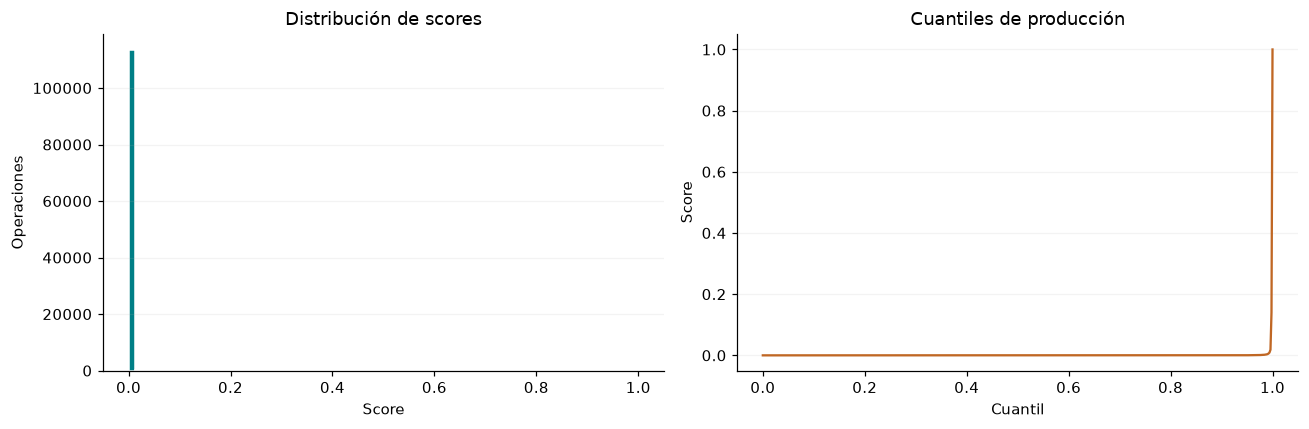

**Entrega verificada:** [entrega_scores.csv](entrega_scores.csv). Incluye 113.923 scores en el orden original y una única columna `score`. Su procedencia queda registrada en [auditoria_entrega.json](estudio_datos/comparativa_full/resultados/auditoria_entrega.json). La comprobación completa del modelo recargado y sus cinco tiempos están en [tiempos_inferencia_entrega.json](estudio_datos/comparativa_full/resultados/tiempos_inferencia_entrega.json).

In [9]:
display(tabla_entrega["score"].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
).to_frame("score"))
percentiles = np.linspace(0, 1, 501)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(tabla_entrega["score"], bins=80, color="#007f86", edgecolor="white")
axes[0].set(xlabel="Score", ylabel="Operaciones", title="Distribución de scores")
axes[1].plot(percentiles, np.quantile(tabla_entrega["score"], percentiles), color="#c06724")
axes[1].set(xlabel="Cuantil", ylabel="Score", title="Cuantiles de producción")
for ax in axes:
    ax.grid(axis="y", alpha=0.15)
plt.tight_layout()
plt.show()
display(Markdown(
    "**Entrega verificada:** [entrega_scores.csv](entrega_scores.csv). "
    "Incluye 113.923 scores en el orden original y una única columna `score`. "
    "Su procedencia queda registrada en "
    "[auditoria_entrega.json](estudio_datos/comparativa_full/resultados/auditoria_entrega.json). "
    "La comprobación completa del modelo recargado y sus cinco tiempos están en "
    "[tiempos_inferencia_entrega.json](estudio_datos/comparativa_full/resultados/tiempos_inferencia_entrega.json)."
))